In [1]:
from load_basics import *
from nbodykit.lab import *
from nbodykit.source.catalog import BigFileCatalog
from nbodykit.lab import ArrayCatalog, FFTPower
import h5py, glob
# from astrid_utils import *
from astropy.cosmology import Planck15 as cosmo
from astropy import units
from bigfile import BigFile

In [2]:
from colossus.cosmology import cosmology
cosmo_col = cosmology.setCosmology('myCosmo', params = cosmology.cosmologies['planck15'], Neff = 0.0, relspecies=False)
print(cosmo_col)
print(cosmo_col.growthFactor(99))


Cosmology "myCosmo" 
    flat = True, Om0 = 0.3089, Ode0 = 0.6911, Ob0 = 0.0486, H0 = 67.74, sigma8 = 0.8159, ns = 0.9667
    de_model = lambda, relspecies = False, Tcmb0 = 2.7255, Neff = 0.0000, powerlaw = False
0.01275059130616813


In [3]:
(1/78.427)

0.012750710852130006

## MP-Gadget

In [4]:
from colossus.cosmology import cosmology
cosmo_mp = cosmology.setCosmology('myCosmo', params = cosmology.cosmologies['planck15'])
print(cosmo_mp)
print(cosmo_mp.growthFactor(99))


Cosmology "myCosmo" 
    flat = True, Om0 = 0.3089, Ode0 = 0.6910, Ob0 = 0.0486, H0 = 67.74, sigma8 = 0.8159, ns = 0.9667
    de_model = lambda, relspecies = True, Tcmb0 = 2.7255, Neff = 3.0460, powerlaw = False
0.013001689827184007


In [5]:
def gen_mesh_mp(fdir , Lbox=400, Nmesh=128, comp=False):
    bf = BigFile(fdir)
    aa = bf["Header"].attrs['Time'][0]
    zz = 1/aa - 1
    pos = bf["1/Position"][:]
    vel = bf["1/Velocity"][:]
    cat = ArrayCatalog({'Position' : pos, 'Velocity' : vel}, BoxSize=[Lbox, Lbox, Lbox])
    cat["Vx"] = vel[:, 0] # to peculiar velocity in km/s
    cat["Vy"] = vel[:, 1]
    cat["Vz"] = vel[:, 2]
    mesh_rho = cat.to_mesh(compensated=comp, resampler='tsc',Nmesh=Nmesh,position='Position', interlaced=True)
    mesh_vx = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vx', Nmesh=Nmesh, interlaced=True)
    mesh_vy = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vy', Nmesh=Nmesh, interlaced=True)
    mesh_vz = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vz', Nmesh=Nmesh, interlaced=True)
    return mesh_rho, mesh_vx, mesh_vy, mesh_vz, zz


In [6]:
def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk, ps

def compute_cross(mesh1, mesh2):
    k0_1, Pk_1, ps1 = compute_power(mesh1)
    k0_2, Pk_2, ps2 = compute_power(mesh2)
    
    rr = FFTPower(mesh1,second = mesh2, mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']

    eta = ps / np.sqrt(ps1 * ps2)
    return k0_1, ps1, ps2, eta

In [7]:
def downsize(one_plus_delta, factor):
    """
    Downsize the mesh by a factor of `factor`.
    """
    if factor == 1:
        return one_plus_delta
    elif factor < 1:
        raise ValueError("Downsize factor must be >= 1")
    
    new_shape = (one_plus_delta.shape[0] // factor, 
                 one_plus_delta.shape[1] // factor, 
                 one_plus_delta.shape[2] // factor)
    
    downsampled = one_plus_delta.reshape(new_shape[0], factor, \
        new_shape[1], factor, new_shape[2], factor).mean(axis=(1,3,5))
    return downsampled

In [8]:
delta_lin = np.load("linear_density_noneutrino.npy")


In [9]:
bf = BigFile("/home/nianyic/scratch1/FMsims/mpgadget-200/ICS/IC")
bf["Header"].attrs['Time'][0]

0.005

In [10]:
kvals = []
p_ratio = []
cross = []
zlist = []
for snap in [0,2,4, 6, 8]:
    icdir = "/home/nianyic/scratch1/FMsims/mpgadget-200/output/PART_%03d"%snap
    mesh_rho0, mesh_vx0, mesh_vy0, mesh_vz0, zz = gen_mesh_mp(icdir, Lbox=400, Nmesh=128, comp=True)
    delta0 = (mesh_rho0.paint(mode='real').value -1) / cosmo_mp.growthFactor(zz)
    meshlin = ArrayMesh(downsize(delta_lin, 1), BoxSize=400.0)
    mesh0 = ArrayMesh(downsize(delta0.astype(np.float64), 1), BoxSize=400.0)
    k0, ps1, ps2, eta = compute_cross(meshlin, mesh0)   
    kvals.append(k0)
    p_ratio.append(ps2 / ps1)
    cross.append(eta)
    zlist.append(zz)



/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  
/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:13: RuntimeWarning: invalid value encountered in true_divide
  del sys.path[0]


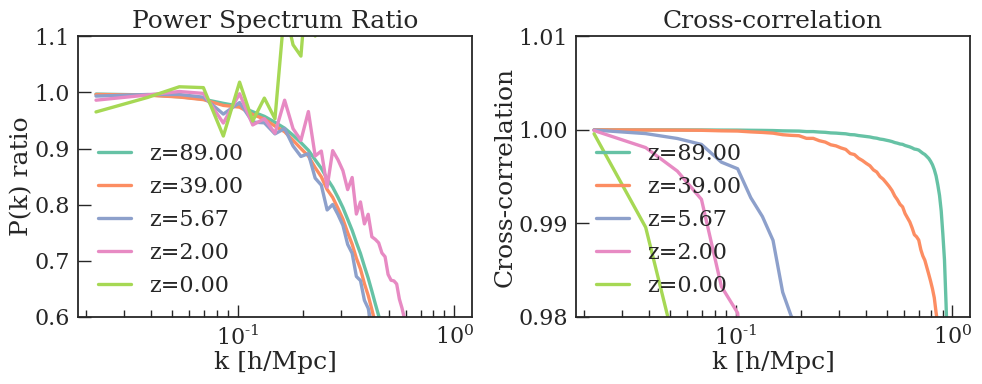

In [11]:
    
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, zz in enumerate(zlist[:]):
    ax[0].plot(kvals[i], p_ratio[i], label=f'z={zz:.2f}')
    ax[1].plot(kvals[i], cross[i], label=f'z={zz:.2f}')
ax[0].set_xscale('log')
#ax[0].set_yscale('log')
ax[0].set_xlabel('k [h/Mpc]')
ax[0].set_ylabel('P(k) ratio')
ax[0].set_title('Power Spectrum Ratio')
ax[0].legend()
ax[1].set_xscale('log')
ax[1].set_yscale('linear')
ax[1].set_xlabel('k [h/Mpc]')
ax[1].set_ylabel('Cross-correlation')
ax[1].set_title('Cross-correlation')
ax[1].legend()
ax[0].set(ylim=[0.6,1.1])
ax[1].set(ylim=[0.98,1.01])
plt.tight_layout()
plt.show()


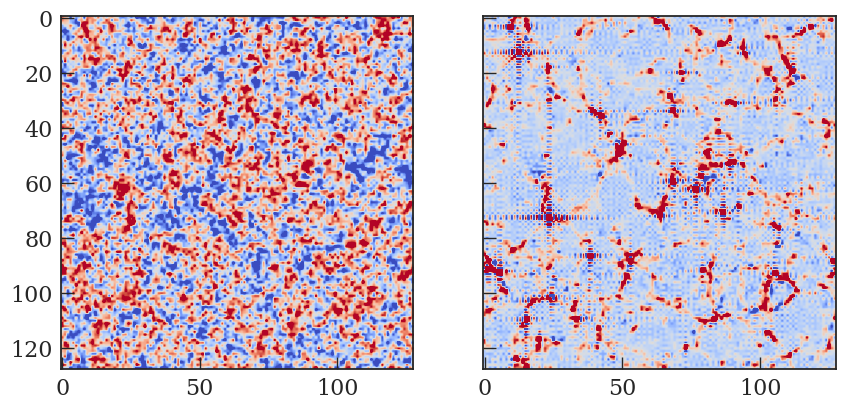

In [12]:
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_lin[:,:,20],vmin=-3, vmax=3, cmap='coolwarm')
ax[1].imshow(delta0[:,:,20],vmin=-3, vmax=3, cmap='coolwarm')

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in true_divide
  This is separate from the ipykernel package so we can avoid doing imports until


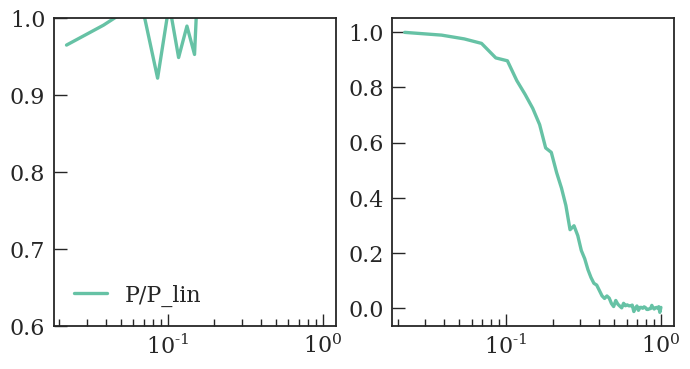

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
# ax[0].plot(k0, ps1)
ax[0].plot(k0, ps2/ps1, label='P/P_lin')

ax[0].set(xscale="log", yscale="linear", ylim=[0.6, 1])

ax[1].plot(k0, eta)
ax[1].set(xscale="log", yscale="linear")
ax[0].legend()

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  
/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in true_divide
  


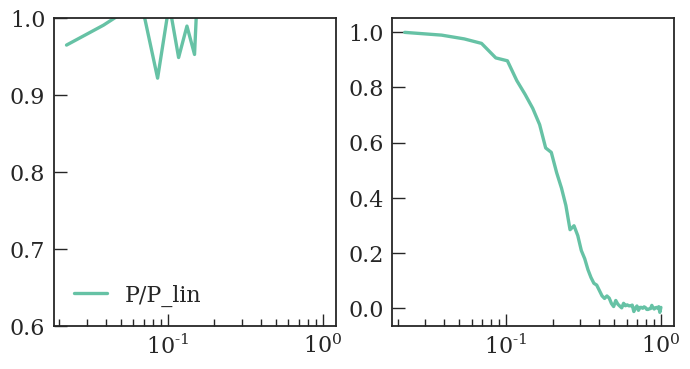

In [14]:
meshlin = ArrayMesh(downsize(delta_lin, 1), BoxSize=400.0)
mesh0 = ArrayMesh(downsize(delta0.astype(np.float64), 1), BoxSize=400.0)

k0, ps1, ps2, eta = compute_cross(meshlin, mesh0)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
# ax[0].plot(k0, ps1)
ax[0].plot(k0, ps2/ps1, label='P/P_lin')

ax[0].set(xscale="log", yscale="linear", ylim=[0.6, 1])

ax[1].plot(k0, eta)
ax[1].set(xscale="log", yscale="linear")
ax[0].legend()

## gadget4 2lpt

In [15]:
from colossus.cosmology import cosmology
cosmo_g4 = cosmology.setCosmology('myCosmo', params = cosmology.cosmologies['planck15'], Neff = 0.0, relspecies=False)
print(cosmo_g4)
print(cosmo_g4.growthFactor(99))

Cosmology "myCosmo" 
    flat = True, Om0 = 0.3089, Ode0 = 0.6911, Ob0 = 0.0486, H0 = 67.74, sigma8 = 0.8159, ns = 0.9667
    de_model = lambda, relspecies = False, Tcmb0 = 2.7255, Neff = 0.0000, powerlaw = False
0.01275059130616813


In [16]:
def gen_mesh_g4(fdir , Lbox=400, Nmesh=128, comp=False):
    bf = h5py.File(fdir, "r")
    aa = bf["Header"].attrs['Time']
    zz = 1/aa - 1
    pos = bf["PartType1/Coordinates"][:]
    vel = bf["PartType1/Velocities"][:]
    cat = ArrayCatalog({'Position' : pos, 'Velocity' : vel}, BoxSize=[Lbox, Lbox, Lbox])
    cat["Vx"] = vel[:, 0] # to peculiar velocity in km/s
    cat["Vy"] = vel[:, 1]
    cat["Vz"] = vel[:, 2]
    mesh_rho = cat.to_mesh(compensated=comp, resampler='tsc',Nmesh=Nmesh,position='Position', interlaced=True)
    mesh_vx = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vx', Nmesh=Nmesh, interlaced=True)
    mesh_vy = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vy', Nmesh=Nmesh, interlaced=True)
    mesh_vz = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vz', Nmesh=Nmesh, interlaced=True)
    return mesh_rho, mesh_vx, mesh_vy, mesh_vz, zz

In [17]:
icdir = "/home/nianyic/scratch1/FMsims/gadget4/2lpt/output/snap_ics_000.hdf5"
mesh_rho0, mesh_vx0, mesh_vy0, mesh_vz0, zz = gen_mesh_g4(icdir, Lbox=400, Nmesh=128, comp=True)
print(zz)
delta_lin = np.load("linear_density.npy")

delta0 = (mesh_rho0.paint(mode='real').value -1) / cosmo_g4.growthFactor(zz)
meshlin = ArrayMesh(downsize(delta_lin, 1), BoxSize=400.0)
mesh0 = ArrayMesh(downsize(delta0.astype(np.float64), 1), BoxSize=400.0)
k0, ps1, ps2, eta = compute_cross(meshlin, mesh0)   

99.0


/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


0.999810116144095


/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in true_divide
  This is separate from the ipykernel package so we can avoid doing imports until


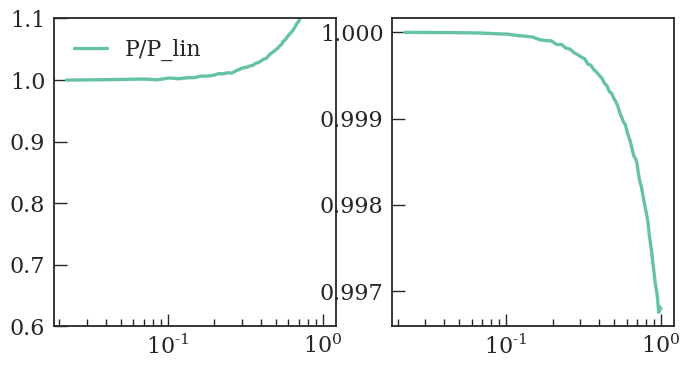

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
# ax[0].plot(k0, ps1)
ax[0].plot(k0, ps2/ps1, label='P/P_lin')
print(ps2[1]/ps1[1])

ax[0].set(xscale="log", yscale="linear", ylim=[0.6, 1.1])

ax[1].plot(k0, eta)
ax[1].set(xscale="log", yscale="linear")
ax[0].legend()

In [ ]:
kvals = []
p_ratio = []
cross = []
zlist = []
for snap in [0,2,4, 6, 8]:
    icdir = "/home/nianyic/scratch1/FMsims/gadget4/2lpt/output/snap_%03d.hdf5"%snap
    mesh_rho0, mesh_vx0, mesh_vy0, mesh_vz0, zz = gen_mesh_g4(icdir, Lbox=400, Nmesh=128, comp=True)
    delta0 = (mesh_rho0.paint(mode='real').value -1) / cosmo_g4.growthFactor(zz) * cosmo_g4.growthFactor(0)
    meshlin = ArrayMesh(downsize(delta_lin, 1), BoxSize=400.0)
    mesh0 = ArrayMesh(downsize(delta0.astype(np.float64), 1), BoxSize=400.0)
    k0, ps1, ps2, eta = compute_cross(meshlin, mesh0)   
    kvals.append(k0)
    p_ratio.append(ps2 / ps1)
    cross.append(eta)
    zlist.append(zz)

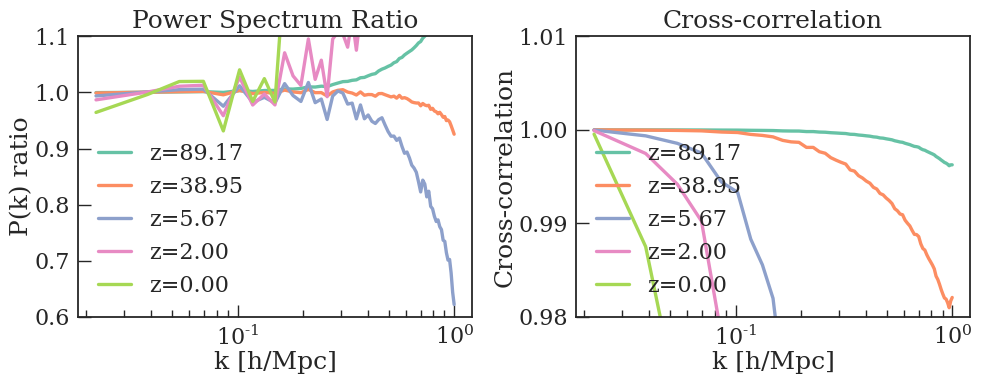

In [ ]:
    
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, zz in enumerate(zlist[:]):
    ax[0].plot(kvals[i], p_ratio[i], label=f'z={zz:.2f}')
    ax[1].plot(kvals[i], cross[i], label=f'z={zz:.2f}')
ax[0].set_xscale('log')
#ax[0].set_yscale('log')
ax[0].set_xlabel('k [h/Mpc]')
ax[0].set_ylabel('P(k) ratio')
ax[0].set_title('Power Spectrum Ratio')
ax[0].legend()
ax[0].set(ylim=[0.6, 1.1])
ax[1].set_xscale('log')
ax[1].set_yscale('linear')
ax[1].set_xlabel('k [h/Mpc]')
ax[1].set_ylabel('Cross-correlation')
ax[1].set_title('Cross-correlation')
ax[1].set(ylim=[0.98, 1.01])
ax[1].legend()
plt.tight_layout()
plt.show()


0.024557689534723585
[0.0001     0.00010163 0.00010328 0.00010496 0.00010667]
[0.00628319 0.00644027 0.00660128 0.00676631 0.00693547]
(486,)
(1000,)


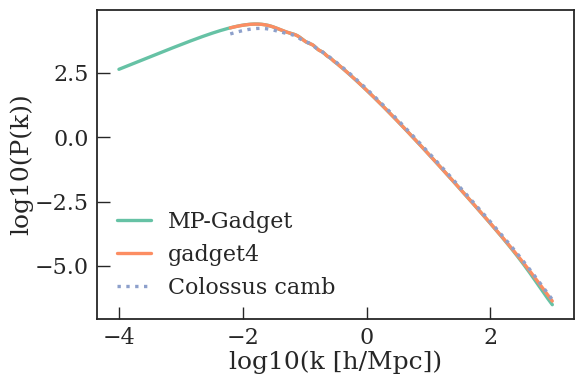

In [ ]:
ps1 = np.loadtxt("linearpowerspec_Planck15.txt", unpack=True)
# ps2 = np.loadtxt("/home/nianyic/scratch1/FMsims/gadget4/2lpt/input_spectrum_PLANCK15.txt", unpack=True)
ps2 = np.loadtxt("/home/nianyic/scratch1/FMsims/gadget4/2lpt/output/inputspec_snap.txt", unpack=True, skiprows=1, usecols=(0,1))

# ps2[0] = np.power(10, ps2[0])
# ps2[1] = np.power(10, ps2[1])
ps2[1] /= ( ps2[0] * ps2[0] * ps2[0] / (2 * np.pi * np.pi) )
# ps2[1] /= cosmo_col.growthFactor(137)

print(ps1[1][1]/ps2[1][1])
print(ps1[0][:5])
print(ps2[0][:5])


P_camb = cosmo_g4.matterPowerSpectrum(k=ps2[0], model = 'camb')
print(P_camb.shape)
print(ps1[0].shape)


fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(np.log10(ps1[0]), np.log10(ps1[1]), label='MP-Gadget')
ax.plot(np.log10(ps2[0]), np.log10(ps2[1]), label='gadget4')

ax.plot(np.log10(ps2[0]), np.log10(P_camb), label='Colossus camb', linestyle=':')
ax.set_xlabel('log10(k [h/Mpc])')
ax.set_ylabel('log10(P(k))')
ax.legend()
plt.tight_layout()
plt.show()


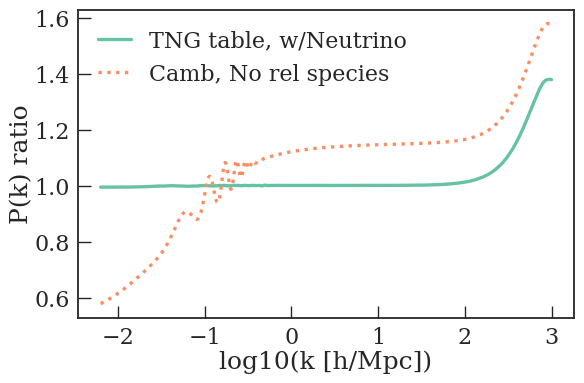

In [ ]:
# ps1 = np.loadtxt("../mpgadget-200/linearpowerspec_Planck15_noneutrino.txt", unpack=True)
# ps2 = np.loadtxt("/home/nianyic/scratch1/FMsims/gadget4/2lpt/input_spectrum_PLANCK15.txt", unpack=True)
# ps2[0] = np.power(10, ps2[0])
# ps2[1] = np.power(10, ps2[1])
# ps2[1] /= ( ps2[0] * ps2[0] * ps2[0] / (2 * np.pi * np.pi) )

ps1_2 = np.interp(ps2[0], ps1[0], ps1[1])


fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(np.log10(ps2[0]), ps2[1] / ps1_2, label='TNG table, w/Neutrino')
ax.plot(np.log10(ps2[0]), P_camb / ps1_2, label='Camb, No rel species', linestyle=':')

ax.set_xlabel('log10(k [h/Mpc])')
ax.set_ylabel('P(k) ratio')
ax.legend()
plt.tight_layout()
plt.show()


### clarify radiation/neutrino differences

In [ ]:
from nbodykit.cosmology import Cosmology, LinearPower, Planck15

cosmo1 = Planck15.clone(m_ncdm=[], Omega0_cdm=Planck15.Om0-Planck15.Ob0, P_k_max=1000.)
cosmo1 = cosmo1.match(sigma8=Planck15.sigma8)
k = np.logspace(-4, 3, 1000, endpoint=True)
power = LinearPower(cosmo1, 0, transfer='CLASS')
print(cosmo1.Omega0_m, power.sigma8, cosmo1.Omega0_b, cosmo1.n_s, flush=True)
p = power(k)

# np.savetxt('linearpowerspec_Planck15_noneutrino_gadget4.txt', np.array((k, p)).T)

KeyError: 'N_ur'

In [ ]:
print(Planck15.Omega_ncdm(100), Planck15.Omega_r(0), Planck15.Omega_ur(100))

0.006121238149150384 7.891574797365187e-05 0.00791718578284774


In [160]:
print(cosmo_noneutrino.Om0)

0.30893727996897064


In [156]:
om_p15 = cosmo_p15.Om0
cosmo_p15 = cosmology.setCosmology('planck15')
print(cosmo_p15.Onu(0), cosmo_p15.Ogamma(0), cosmo_p15.Or(0))

cosmo_norel = cosmology.setCosmology('myCosmo', params = cosmology.cosmologies['planck15'], Neff = 0.0, relspecies=False, Om0 = om_p15 + cosmo_p15.Or(0), flat=True)
cosmo_noneutrino = cosmology.setCosmology('myCosmo2', params = cosmology.cosmologies['planck15'], Neff = 0.0, Om0 = om_p15 + cosmo_p15.Onu(0), flat=True)

k_p15, pk_p15 = np.loadtxt("linearpowerspec_Planck15.txt", unpack=True)
k_noneutrino, pk_noneutrino = np.loadtxt("../mpgadget/linearpowerspec_Planck15_noneutrino.txt", unpack=True)


p_camb_norel = cosmo_norel.matterPowerSpectrum(k=k_p15, model = 'camb')
p_camb_noneutrino = cosmo_noneutrino.matterPowerSpectrum(k=k_p15, model = 'camb')
p_camb_p15 = cosmo_p15.matterPowerSpectrum(k=k_p15, model = 'camb')


3.727996897061188e-05 5.389078568216608e-05 9.117075465277797e-05


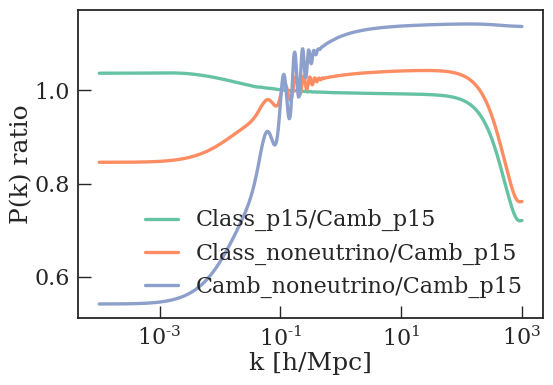

In [153]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k_p15, pk_p15 / p_camb_p15, label='Class_p15/Camb_p15')
ax.plot(k_p15, pk_noneutrino / p_camb_p15, label='Class_noneutrino/Camb_p15')
# ax.plot(k_p15, p_camb_norel / p_camb_p15, label='Camb_norel/Camb_p15', linestyle='-')
ax.plot(k_p15, p_camb_noneutrino / p_camb_p15, label='Camb_noneutrino/Camb_p15', linestyle='-')

ax.set_xlabel('k [h/Mpc]')
ax.set_ylabel('P(k) ratio')
ax.set(xscale='log', yscale='linear')
ax.legend()
plt.show()

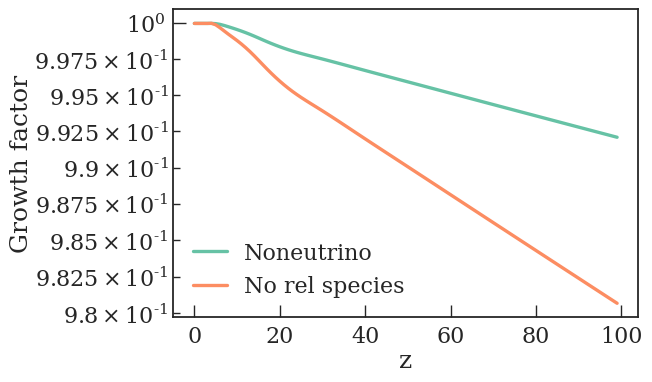

In [145]:
zlist = np.linspace(0, 99, 100)
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
# ax.plot(zlist, , label='P15')
ax.plot(zlist, cosmo_noneutrino.growthFactor(zlist)/cosmo_p15.growthFactor(zlist), label='Noneutrino')
ax.plot(zlist, cosmo_norel.growthFactor(zlist)/cosmo_p15.growthFactor(zlist), label='No rel species')
ax.set_xlabel('z')
ax.set_ylabel('Growth factor')
ax.legend()
ax.set(yscale="log")
plt.show()